In [1]:
import os
import sys

project_root = os.path.abspath("..")   # if the notebook is inside notebooks/
sys.path.insert(0, project_root)
print(project_root)

c:\Projects\Service Event Framework\Improvement\code


In [28]:
import os
import numpy as np
import pandas as pd
from utils.dbconnection import engine
from pathlib import Path
from utils.config import config
import seaborn as sns

Read Files

In [3]:
parent = os.path.join(config.locations.inputs, "material_as_parent_child.csv")
df_parent = pd.read_csv(parent)
df_parent.columns = ['parent_material', 'child_material']
df_parent.head()

,parent_material,child_material
0,100223,109283
1,101110,153184
2,101110,155425
3,101110,156295
4,101110,29122444


In [4]:
xlsx_path = os.path.join(config.locations.outputs, "service_event_analysis.xlsx")
df = pd.read_excel(xlsx_path, sheet_name="event_material")
df.head()

,DServiceEventID,Serviceeventcode,ServiceEventName,AND_OR,Priority,confidence,Itemnumber,MaterialName,MaterialGroup,MaterialGroupDescription
0,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10,107033,BLADE BEARING ø54,31,"Bearings, Blade TRAC"
1,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10,760306,BLADE BEARING MODULE,327,Nacelle modules and
2,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10,76221907,BLADE BEARING MODULE,30,Bearings
3,1,BladeBearingReplace,Blade Bearing Replacement,OR,9.6,10,76221971,BLADE BEARING MODULE,327,Nacelle modules and
4,4,GenBearReplace,Generator Bearing Replacement,OR,7.8,10,103566,"BEARING,BALL,6344 MC3,220 mm",30,Bearings


Merge on events

In [7]:
df_parent.columns

Index(['parent_material', 'child_material'], dtype='str')

In [14]:
req_cols = ['Serviceeventcode','Itemnumber','MaterialName']

m1 = df[req_cols].merge(df_parent, left_on='Itemnumber', right_on='parent_material', how='left')
m1.dropna(inplace=True)
m2 = m1.merge(df[req_cols], right_on='Itemnumber', left_on='child_material', how='inner', suffixes=['_parent', '_child'])
m2.head()

,Serviceeventcode_parent,Itemnumber_parent,MaterialName_parent,parent_material,child_material,Serviceeventcode_child,Itemnumber_child,MaterialName_child
0,BladeBearingReplace,760306,BLADE BEARING MODULE,760306,764330,BBGreasePumpReplace,764330,LUB SYS F. BLADE BEARING 2 MW
1,BladeBearingReplace,76221971,BLADE BEARING MODULE,76221971,29102244,AnchorAssyReplace,29102244,"ANCHOR,50 mm,10 mm,SS,4"
2,BladeBearingReplace,76221971,BLADE BEARING MODULE,76221971,51605002,WICctModuleReplace,51605002,CT6050 BLADE CONTROLLER
3,BladeBearingReplace,76221971,BLADE BEARING MODULE,76221971,781824,TorqueArmBushReplace,781824,"TORQUE ARM, MOUNTED"
4,GenBearReplace,105244,LS 3MW GEN BEAR MK61S/71S A,105244,105203,GenBearReplace,105203,"BEARING,BALL,BB1-7069C,180 mm"


In [36]:
m2.shape

(4273, 8)

In [17]:
m2.head(10)

,Serviceeventcode_parent,Itemnumber_parent,MaterialName_parent,parent_material,child_material,Serviceeventcode_child,Itemnumber_child,MaterialName_child
0,BladeBearingReplace,760306,BLADE BEARING MODULE,760306,764330,BBGreasePumpReplace,764330,LUB SYS F. BLADE BEARING 2 MW
1,BladeBearingReplace,76221971,BLADE BEARING MODULE,76221971,29102244,AnchorAssyReplace,29102244,"ANCHOR,50 mm,10 mm,SS,4"
2,BladeBearingReplace,76221971,BLADE BEARING MODULE,76221971,51605002,WICctModuleReplace,51605002,CT6050 BLADE CONTROLLER
3,BladeBearingReplace,76221971,BLADE BEARING MODULE,76221971,781824,TorqueArmBushReplace,781824,"TORQUE ARM, MOUNTED"
4,GenBearReplace,105244,LS 3MW GEN BEAR MK61S/71S A,105244,105203,GenBearReplace,105203,"BEARING,BALL,BB1-7069C,180 mm"
5,GenBearReplace,70590033,PH ASS BEARING HYBRID DE 3MW,70590033,29527,GenGreaseConsumption,29527,"GREASE,KLUBERPLEX BEM 41-132,1KG"
6,GenBearReplace,70590033,PH ASS BEARING HYBRID DE 3MW,70590033,34744,GenBearReplace,34744,"BEARING,BALL,6334/HC5C3PS0VA970,170 mm"
7,GenBearReplace,70590034,PH ASS BEAR HYBRID NDE3MW 50Hz,70590034,29527,GenGreaseConsumption,29527,"GREASE,KLUBERPLEX BEM 41-132,1KG"
8,GenBearReplace,70590034,PH ASS BEAR HYBRID NDE3MW 50Hz,70590034,34744,GenBearReplace,34744,"BEARING,BALL,6334/HC5C3PS0VA970,170 mm"
9,PitchCylinderReplace,108613,"CYLINDER,HYDRAULIC,125 mm,80 mm,922 mm",108613,108614,PitchCylinderReplace,108614,"CYLINDER,HYDRAULIC,125 mm,80 mm,922 mm"


In [22]:
req_cols = ['Serviceeventcode_parent','Serviceeventcode_child']
m2f = m2[req_cols].drop_duplicates(ignore_index=True)
m2f.head()

,Serviceeventcode_parent,Serviceeventcode_child
0,BladeBearingReplace,BBGreasePumpReplace
1,BladeBearingReplace,AnchorAssyReplace
2,BladeBearingReplace,WICctModuleReplace
3,BladeBearingReplace,TorqueArmBushReplace
4,GenBearReplace,GenBearReplace


In [ ]:
m2fg = m2f.groupby(['Serviceeventcode_parent'])['Serviceeventcode_child'].count().reset_index(name='child_count').sort_values(by='child_count', ascending=False)
m2fg.head()

,Serviceeventcode_parent,child_count
25,ConvertorModReplace,32
69,HydManifoldReplace,24
75,HydPumpReplace,15
74,HydPumpMotorAssyReplace,13
45,GearOilFilterReplace,13
...,...,...
142,TowerSectionModuleReplace,1
150,YawGearReplace,1
151,YawGreaseWheel_mat,1
152,YawModuleVibrationSensorReplace,1


In [35]:
m2fg.loc[m2fg['child_count']==5]

,Serviceeventcode_parent,child_count
79,InternalChainHoistAssembly,5
78,HydraulicTankReplace,5
66,HubControllerReplace,5
5,BBGreaseConsumption,5
140,TowerRailLadder,5
94,PPRCBReplace,5
148,YawClawBeamModuleReplace,5
109,PowerPlantControllerReplace,5


<Axes: xlabel='child_count', ylabel='Count'>

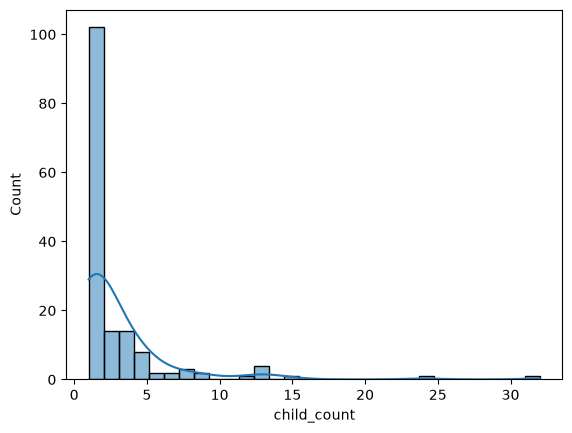

In [33]:
sns.histplot(m2fg['child_count'], bins=30, kde=True)

In [37]:
df_save_dict = {
    'event_parent_child': m2,
    'event_materialGroup': m2fg,
}

In [38]:
from pathlib import Path

output_dir = Path(config.locations.outputs)
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "disparity_parent_child_analysis.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for sheet_name, df_sheet in df_save_dict.items():
        if isinstance(df_sheet, pd.DataFrame):
            df_sheet.to_excel(writer, sheet_name=sheet_name, index=False)
        else:
            pd.DataFrame(df_sheet).to_excel(writer, sheet_name=sheet_name, index=False)

excel_path

WindowsPath('C:/Projects/Service Event Framework/Improvement/code/data/outputs/disparity_parent_child_analysis.xlsx')